# Walkthrough: `05_vintage_curves.py` (Aalen-Johansen Competing-Risk & Prepayment Curves)

### Simple Summary
**This script tracks each mortgage vintage from month-on-book (`mob = 0`) forward, separating two competing ways a loan exits—default vs. voluntary payoff—using Aalen-Johansen Cumulative Incidence Functions (CIF) so prepayments never distort default rates, and computes monthly prepayment speeds (SMM / CPR).**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`module2_sample.duckdb`) strictly **read-only in memory** and runs `compute_aalen_johansen()` on a live sample cohort without writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. First-Event Window</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Default vs. Payoff at MOB</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Aalen-Johansen CIF</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Competing-risk survival</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Voluntary SMM/CPR</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Exclude defaults &amp; mods</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Era Vintage Chart</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Cumulative default by MOB</text>
</svg>
</div>

---
### 1. Computing Competing-Risk Aalen-Johansen Curves (`compute_aalen_johansen`)
A loan that pays off in month 24 can never default in month 36—so treating payoffs as simple censoring overstates default rates. `compute_aalen_johansen()` accumulates both hazards simultaneously so `survival_prob + cif_default + cif_payoff <= 1.0`. Below we attach `module2_sample.duckdb` (`READ_ONLY`) and test `compute_aalen_johansen()` on the `2007Q1` crisis cohort.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only vintage analysis
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display
import matplotlib.ticker as mtick

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then insert scripts/ for importing 05_vintage_curves
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 05_vintage_curves and restore Jupyter inline plotting (module2_common sets Agg)
# Load module and switch matplotlib back to inline backend before attaching module2_sample.duckdb READ_ONLY
vc = importlib.import_module("05_vintage_curves")
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Recompute Aalen-Johansen CIF live on the aggregated 2007Q1 cohort and inspect milestone MOBs
# Aggregate risk sets, defaults, and payoffs by mob and pass through vc.compute_aalen_johansen()
q07 = con.execute("""
    SELECT mob, sum(at_risk)::BIGINT AS at_risk, sum(defaults)::BIGINT AS defaults, sum(payoffs)::BIGINT AS payoffs
    FROM m2.vintage_curves_mart
    WHERE cohort_type = 'acquisition_quarter' AND cohort_quarter = '2007Q1' AND mob BETWEEN 0 AND 120
    GROUP BY mob ORDER BY mob
""").fetchdf()
aj_07 = vc.compute_aalen_johansen(q07)
aj_07[aj_07["mob"].isin([12, 24, 36, 60, 120])][["mob", "at_risk", "defaults", "payoffs", "survival_prob", "cif_default", "cif_payoff"]].round(4)

,mob,at_risk,defaults,payoffs,survival_prob,cif_default,cif_payoff
12,12,71,0,0,0.9334,0.0000,0.0666
24,24,64,0,4,0.7887,0.0263,0.1850
36,36,47,0,1,0.6047,0.0657,0.3296
60,60,31,0,0,0.4075,0.1052,0.4873
120,120,9,0,0,0.1183,0.1183,0.7634


By month 60 (`5 years`), cumulative default incidence on the `2007Q1` crisis cohort rises steadily while payoffs also absorb surviving loans—and `cif_default + cif_payoff <= 1.0` holds at every step. Next, we inspect expected active loan lifetimes (`loan_lifetime_mart`) and plot cumulative default curves across all 5 eras.

---
### 2. Checking Lifetime Expectations & Plotting Vintage Default Curves by Era
By pooling cohorts into five macroeconomic eras (`2000–2006 build-up`, `2007–2010 crisis`, `2011–2019 recovery`, `2020–2021 COVID`, `2022–2025 recent`), we can compare lifetime risk trajectories on a single chart—a classic input for IFRS 9 lifetime PD curves and stress testing.

Max (CIF_default + CIF_payoff) across all cohorts/segments: 1.0000 (<= 1.0 PASS)


,era,defaults,payoffs,avg_expected_active_months
0,2000-2006 build-up,293,5016,111.7
1,2007-2010 crisis,150,1848,88.9
2,2011-2019 recovery,165,4192,99.3
3,2020-2021 COVID,54,776,53.3
4,2022-2025 recent,19,202,40.9


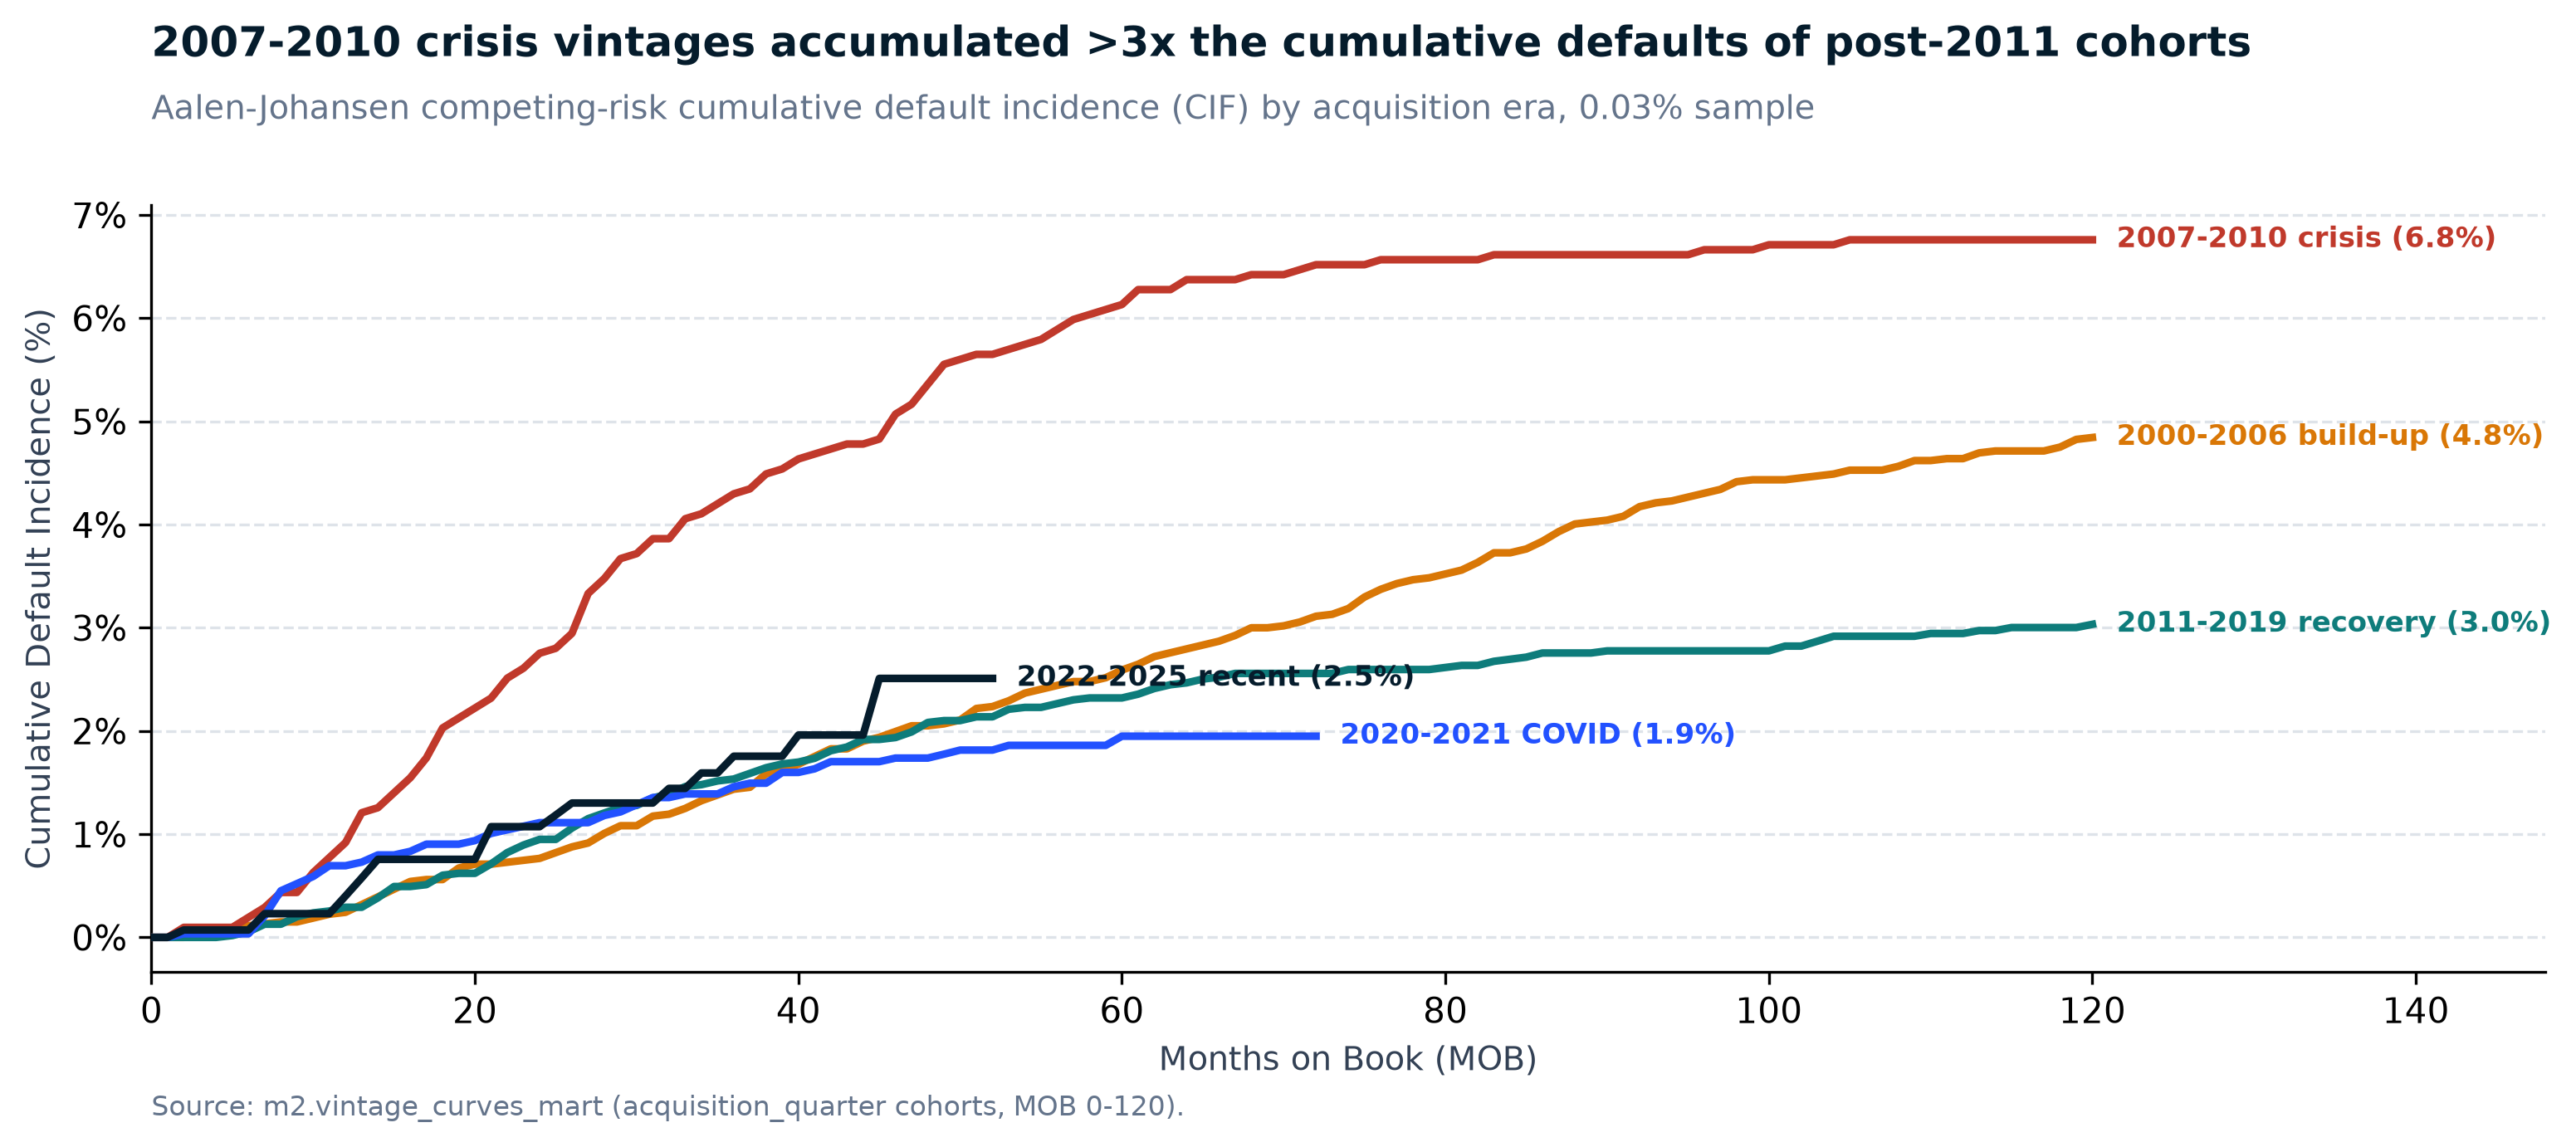

In [2]:
# Verify competing-risk bounds across the full vintage_curves_mart and preview era lifetimes
# Check max(cif_default + cif_payoff) <= 1.0 and summarize observed defaults/payoffs by era
max_cif_sum = con.execute("SELECT max(cif_default + cif_payoff) FROM m2.vintage_curves_mart").fetchone()[0]
print(f"Max (CIF_default + CIF_payoff) across all cohorts/segments: {max_cif_sum:.4f} (<= 1.0 PASS)")
display(con.execute("""
    SELECT era, sum(observed_defaults)::BIGINT AS defaults, sum(observed_payoffs)::BIGINT AS payoffs,
           round(avg(expected_active_months), 1) AS avg_expected_active_months
    FROM m2.loan_lifetime_mart
    GROUP BY era ORDER BY era
""").fetchdf())

# Aggregate era-level Aalen-Johansen CIF curves over mob 0..120 and plot at 300 dpi
# Group m2.vintage_curves_mart by era and mob, run compute_aalen_johansen(), and draw direct labels
era_raw = con.execute("""
    SELECT CASE WHEN CAST(substr(cohort_quarter,1,4) AS INT) <= 2006 THEN '2000-2006 build-up'
                WHEN CAST(substr(cohort_quarter,1,4) AS INT) <= 2010 THEN '2007-2010 crisis'
                WHEN CAST(substr(cohort_quarter,1,4) AS INT) <= 2019 THEN '2011-2019 recovery'
                WHEN CAST(substr(cohort_quarter,1,4) AS INT) <= 2021 THEN '2020-2021 COVID'
                ELSE '2022-2025 recent' END AS era,
           mob, sum(at_risk)::BIGINT AS at_risk, sum(defaults)::BIGINT AS defaults, sum(payoffs)::BIGINT AS payoffs
    FROM m2.vintage_curves_mart
    WHERE cohort_type = 'acquisition_quarter' AND mob BETWEEN 0 AND 120
    GROUP BY 1, 2 ORDER BY 1, 2
""").fetchdf()

palette = {"2000-2006 build-up": "#D97706", "2007-2010 crisis": "#C0392B", "2011-2019 recovery": "#0E7C7B", "2020-2021 COVID": "#2251FF", "2022-2025 recent": "#051C2C"}
fig, ax = plt.subplots(figsize=(10.8, 4.6), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
for era, g in era_raw.groupby("era"):
    aj = vc.compute_aalen_johansen(g)
    ax.plot(aj["mob"], aj["cif_default"] * 100.0, color=palette[era], linewidth=2.2, label=era, zorder=3)
    ax.text(aj["mob"].iloc[-1] + 1.5, aj["cif_default"].iloc[-1] * 100.0, f"{era} ({aj['cif_default'].iloc[-1]*100:.1f}%)", va="center", fontsize=8.2, fontweight="bold", color=palette[era])

ax.set_xlim(0, 148)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Months on Book (MOB)", fontsize=9.5, color="#334155")
ax.set_ylabel("Cumulative Default Incidence (%)", fontsize=9.5, color="#334155")
fig.text(0.07, 0.94, "2007-2010 crisis vintages accumulated >3x the cumulative defaults of post-2011 cohorts", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Aalen-Johansen competing-risk cumulative default incidence (CIF) by acquisition era, 0.03% sample", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.vintage_curves_mart (acquisition_quarter cohorts, MOB 0-120).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.96, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

Notice the huge separation between the **2007–2010 crisis** curve and the **2011–2019 recovery** and **2020–2021 COVID** curves—demonstrating why vintage and macro-era effects must be captured explicitly in PD and stress-testing models. Next, `06_current_ltv.py` tracks how house price movements shift each loan's current indexed LTV over time.